In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os
from cycler import cycler

semilla = 42
random.seed(semilla)
np.random.seed(semilla)

AZULES = ["#08306b", "#2171b5", "#6baed6", "#c6dbef"]
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=AZULES),
    "image.cmap": "Blues",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Cargar Datos

In [22]:
jp = pd.read_csv("db/2_unido/jugador_partido.csv", low_memory=False)
partidos = pd.read_csv("db/2_unido/partidos.csv")
def resumen_eda(df):
    resumen = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "pct_nulos": df.isna().mean().mul(100),
        "valores_unicos": df.nunique(),
    })

    resumen["pct_unicos"] = (
        resumen["valores_unicos"] / len(df) * 100
    )

    return resumen.sort_values(
        "pct_nulos", ascending=False
    )


# EDA JP

In [15]:
resumen_eda(jp)

,tipo,nulos,pct_nulos,valores_unicos,pct_unicos
fm_expected_goals_on_target_faced,float64,87921,95.016859,434,0.469027
fm_goals_conceded,float64,86393,93.365538,9,0.009726
fm_expected_goals_on_target_variant,float64,21566,23.306532,257,0.277742
fm_rating_title,float64,6564,7.093762,634,0.685168
tm_pie,object,119,0.128604,3,0.003242
tm_demarcacion,object,49,0.052955,13,0.014049
tm_altura,float64,44,0.047551,37,0.039986
fm_touches_opp_box,float64,34,0.036744,24,0.025937
fm_accurate_passes_total,float64,34,0.036744,143,0.154541
fm_player_id,float64,34,0.036744,1801,1.946354


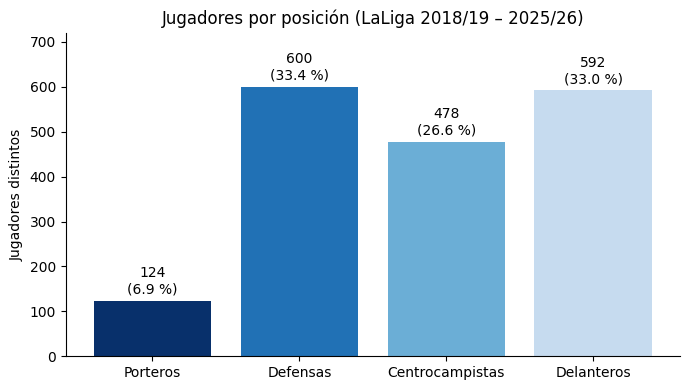

In [24]:
base = jp[jp.fm_player_id.notna()]           # quita las 34 filas sin FotMob
centros = base[base.tm_posicion == "Midfield"]
delanteros = base[base.tm_posicion == "Attack"]
defensas = base[base.tm_posicion == "Defender"]
porteros = base[base.tm_posicion == "Goalkeeper"]

# Gráfico posiciones
grupos = {"Porteros": porteros, "Defensas": defensas,
          "Centrocampistas": centros, "Delanteros": delanteros}

n_jugadores = pd.Series({pos: df["player_id"].nunique() for pos, df in grupos.items()})
pct = n_jugadores / n_jugadores.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(n_jugadores.index, n_jugadores, color=AZULES)
ax.bar_label(barras, labels=[f"{n}\n({p:.1f} %)" for n, p in zip(n_jugadores, pct)], padding=3)
ax.set_ylabel("Jugadores distintos")
ax.set_title("Jugadores por posición (LaLiga 2018/19 – 2025/26)")
ax.set_ylim(0, n_jugadores.max() * 1.2)
plt.tight_layout()
plt.show()

# Distribución datos partidos

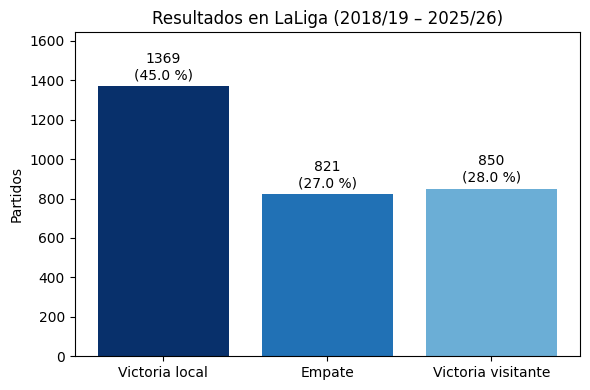

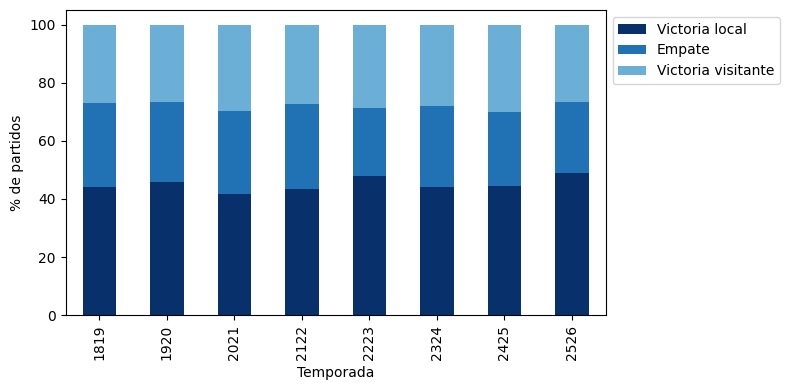

In [7]:
# Resultado desde el punto de vista del local
partidos["resultado"] = np.select(
    [partidos.home_goals > partidos.away_goals,
     partidos.home_goals == partidos.away_goals],
    ["Victoria local", "Empate"],
    default="Victoria visitante",
)
orden = ["Victoria local", "Empate", "Victoria visitante"]
colores = AZULES[:3]          # oscuro = local, medio = empate, claro = visitante

# Distribución total
frec = partidos["resultado"].value_counts().reindex(orden)
pct = frec / frec.sum() * 100
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(orden, frec, color=colores)
ax.bar_label(barras, labels=[f"{n}\n({p:.1f} %)" for n, p in zip(frec, pct)], padding=3)
ax.set_ylabel("Partidos")
ax.set_title("Resultados en LaLiga (2018/19 – 2025/26)")
ax.set_ylim(0, frec.max() * 1.2)
plt.tight_layout()
plt.show()

# Por temporada
tabla = pd.crosstab(partidos["season"], partidos["resultado"], normalize="index")[orden] * 100
ax = tabla.plot(kind="bar", stacked=True, figsize=(8, 4), color=colores)
ax.set_ylabel("% de partidos")
ax.set_xlabel("Temporada")
ax.legend(title="", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()